[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shahin1717/ai-roadmap/blob/main/math/calculus-and-optimization/multivariable-calculus/notebook.ipynb)

# Multivariable Calculus: hands-on

This notebook goes with the [topic README](README.md). You will draw a surface next to its contour lines, see partial derivatives as slopes of slice curves, check that mixed partials agree, test the chain rule along a curve, draw the gradient field and watch it cross the contours at right angles, measure directional derivatives, map a small grid through a Jacobian, compare linear and quadratic approximations, classify critical points with Hessian eigenvalues, see a narrow valley, approach a double integral with Riemann sums, use polar coordinates to get the Gaussian integral, backpropagate through a tiny network, solve linear regression by setting a gradient to zero, and run a per-coordinate gradient check. All data are invented or computed on the spot. It uses NumPy, SymPy, SciPy, and Matplotlib, and runs in under a minute on a CPU.

Numerical checks hold only up to rounding error, so we compare floats with `np.isclose` and `np.allclose`, never `==`.

In [1]:
%matplotlib inline
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import dblquad, quad
from scipy.optimize import fsolve

plt.rcParams["figure.dpi"] = 50
plt.rcParams["axes.titlesize"] = 10
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
np.set_printoptions(precision=6, suppress=True)
x, y, t = sp.symbols("x y t")      # SymPy symbols used in the symbolic cells below


def num_grad(func, p, h=1e-5):
    # Centered finite-difference gradient, one coordinate at a time.
    p = np.asarray(p, dtype=float)
    g = np.zeros_like(p)
    for i in range(len(p)):
        e = np.zeros_like(p)
        e[i] = h
        g[i] = (func(p + e) - func(p - e)) / (2 * h)
    return g

## 1. Surface and contours

A function of two variables, $f(x, y) = x^2 + 2y^2$, is a surface: the height above each point of the $xy$ plane. Contour lines are the curves of equal height. Here are both pictures of the same function (the surface is drawn at low resolution to keep the notebook small).

f(1, 1) = 3


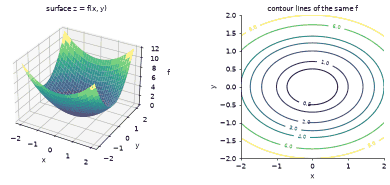

In [2]:
f = lambda x, y: x**2 + 2 * y**2
g1 = np.linspace(-2, 2, 31)
X1, Y1 = np.meshgrid(g1, g1)
g2 = np.linspace(-2, 2, 200)
X2, Y2 = np.meshgrid(g2, g2)

fig = plt.figure(figsize=(9, 3.8))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(X1, Y1, f(X1, Y1), cmap="viridis", alpha=0.9, linewidth=0)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("f"); ax.set_title("surface z = f(x, y)")
ax = fig.add_subplot(1, 2, 2)
cs = ax.contour(X2, Y2, f(X2, Y2), levels=[0.5, 1, 2, 3, 4, 6, 8], cmap="viridis")
ax.clabel(cs, fontsize=7)
ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_title("contour lines of the same f")
fig.tight_layout()
print("f(1, 1) =", f(1, 1))

Contours crowd together where the surface is steep. Because the bowl rises faster in $y$ than in $x$, its contours are ellipses that are narrower along $y$.

## 2. Partial derivatives

To get $f_x$ at $(1, 1)$, freeze $y = 1$ and take the ordinary slope of the slice curve $f(x, 1) = x^2 + 2$. To get $f_y$, freeze $x = 1$ and slope the curve $f(1, y) = 1 + 2y^2$. The picture draws both slice curves on the surface, with their tangent lines.

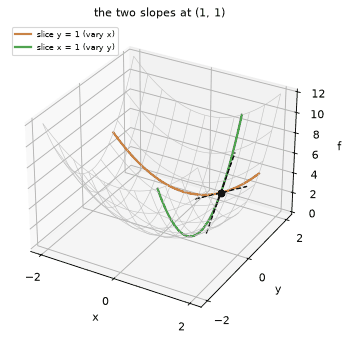

In [3]:
fig = plt.figure(figsize=(5.5, 4.4), dpi=80)
ax = fig.add_subplot(1, 1, 1, projection="3d")
ax.set_xticks([-2, 0, 2]); ax.set_yticks([-2, 0, 2])
ax.plot_wireframe(X1, Y1, f(X1, Y1), rstride=3, cstride=3, color="0.75", linewidth=0.5)
s = np.linspace(-2, 2, 100)
ax.plot(s, np.ones_like(s), f(s, 1), color="tab:orange", lw=2, label="slice y = 1 (vary x)")
ax.plot(np.ones_like(s), s, f(1, s), color="tab:green", lw=2, label="slice x = 1 (vary y)")
d = np.linspace(-0.7, 0.7, 5)
ax.plot(1 + d, np.ones_like(d), 3 + 2 * d, "k--", lw=1.2)        # tangent with slope f_x = 2
ax.plot(np.ones_like(d), 1 + d, 3 + 4 * d, "k--", lw=1.2)        # tangent with slope f_y = 4
ax.plot([1], [1], [3], "ko")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("f"); ax.legend(fontsize=7, loc="upper left")
ax.set_title("the two slopes at (1, 1)")
fig.tight_layout()

The definition is a limit. A table of difference quotients at $(1, 1)$ shows both partials closing in on $2$ and $4$, and SymPy gives the exact answer.

In [4]:
print(f"{'h':>8} {'(f(1+h,1)-f(1,1))/h':>22} {'(f(1,1+h)-f(1,1))/h':>22}")
for h in [0.1, 0.01, 0.001, 1e-4, 1e-5]:
    print(f"{h:>8g} {(f(1 + h, 1) - f(1, 1)) / h:>22.6f} {(f(1, 1 + h) - f(1, 1)) / h:>22.6f}")

f_sym = x**2 + 2 * y**2
print("\nSymPy:", sp.diff(f_sym, x).subs({x: 1, y: 1}), sp.diff(f_sym, y).subs({x: 1, y: 1}))

       h    (f(1+h,1)-f(1,1))/h    (f(1,1+h)-f(1,1))/h
     0.1               2.100000               4.200000
    0.01               2.010000               4.020000
   0.001               2.001000               4.002000
  0.0001               2.000100               4.000200
   1e-05               2.000010               4.000020

SymPy: 2 4


**Mixed partials.** Clairaut's theorem says $f_{xy} = f_{yx}$ when the second partials are continuous. SymPy confirms it on a few functions (the difference simplifies to $0$), and a finite-difference check at one point agrees up to rounding.

In [5]:
for name, expr in {"x^2 y + 3 y^2": x**2 * y + 3 * y**2, "sin(x y)": sp.sin(x * y),
                   "exp(x y^2)": sp.exp(x * y**2), "x^3 y + ln(x y)": x**3 * y + sp.log(x * y)}.items():
    fxy, fyx = sp.diff(expr, x, y), sp.diff(expr, y, x)
    print(f"{name:>16}:  f_xy = {fxy}   equal: {sp.simplify(fxy - fyx) == 0}")

# numeric mixed partial of sin(x y) at (0.7, 1.3) by two difference quotients, both orders
fn = lambda a, b: np.sin(a * b)
h = 1e-4
fx = lambda a, b: (fn(a + h, b) - fn(a - h, b)) / (2 * h)
fy = lambda a, b: (fn(a, b + h) - fn(a, b - h)) / (2 * h)
fxy_num = (fx(0.7, 1.3 + h) - fx(0.7, 1.3 - h)) / (2 * h)      # x first, then y
fyx_num = (fy(0.7 + h, 1.3) - fy(0.7 - h, 1.3)) / (2 * h)      # y first, then x
print(fxy_num, fyx_num, np.isclose(fxy_num, fyx_num, atol=1e-5))

   x^2 y + 3 y^2:  f_xy = 2*x   equal: True
        sin(x y):  f_xy = -x*y*sin(x*y) + cos(x*y)   equal: True
      exp(x y^2):  f_xy = 2*y*(x*y**2 + 1)*exp(x*y**2)   equal: True
 x^3 y + ln(x y):  f_xy = 3*x**2   equal: True
-0.1047026576550536 -0.1047026576550536 True


## 3. The chain rule along a curve

If a point moves along a path $(x(t), y(t))$, then $\dfrac{df}{dt} = f_x x'(t) + f_y y'(t)$. We test it on $f(x, y) = x^2 + 3xy$ with the path $x = t^2$, $y = t + 1$ at $t = 1$ three ways: the chain rule by hand, a finite difference of $f$ along the path, and SymPy after substituting the path.

In [6]:
f_c = x**2 + 3 * x * y
x_t, y_t = t**2, t + 1
chain = (sp.diff(f_c, x) * sp.diff(x_t, t) + sp.diff(f_c, y) * sp.diff(y_t, t)).subs({x: x_t, y: y_t})
direct = sp.diff(f_c.subs({x: x_t, y: y_t}), t)
print("chain rule  :", sp.simplify(chain), "  at t = 1:", chain.subs(t, 1))
print("substitution:", sp.expand(direct), "  at t = 1:", direct.subs(t, 1))

along = sp.lambdify(t, f_c.subs({x: x_t, y: y_t}))
h = 1e-6
print("finite difference at t = 1:", (along(1 + h) - along(1 - h)) / (2 * h))
print("all agree:", np.isclose(float(chain.subs(t, 1)), (along(1 + h) - along(1 - h)) / (2 * h)))

chain rule  : t*(4*t**2 + 9*t + 6)   at t = 1: 19
substitution: 4*t**3 + 9*t**2 + 6*t   at t = 1: 19
finite difference at t = 1: 19.000000000435335
all agree: True


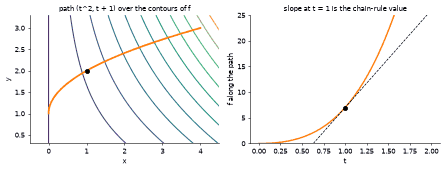

In [7]:
fc = sp.lambdify((x, y), f_c)
tt = np.linspace(0, 2, 200)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
Xc, Yc = np.meshgrid(np.linspace(-0.5, 4.5, 200), np.linspace(0.3, 3.3, 200))
cs = ax[0].contour(Xc, Yc, fc(Xc, Yc), levels=12, cmap="viridis")
ax[0].plot(tt**2, tt + 1, color="tab:orange", lw=2.5)
ax[0].plot([1], [2], "ko"); ax[0].set_xlabel("x"); ax[0].set_ylabel("y"); ax[0].set_title("path (t^2, t + 1) over the contours of f")
ax[1].plot(tt, along(tt), color="tab:orange", lw=2)
slope = float(chain.subs(t, 1))
ax[1].plot(tt, along(1) + slope * (tt - 1), "k--", lw=1)
ax[1].set_ylim(0, 25)
ax[1].plot([1], [along(1)], "ko"); ax[1].set_xlabel("t"); ax[1].set_ylabel("f along the path")
ax[1].set_title("slope at t = 1 is the chain-rule value")
fig.tight_layout()

## 4. The gradient field and directional derivatives

The gradient $\nabla f = (f_x, f_y)$ at every point is an arrow. For the bowl it is $(2x, 4y)$. Drawn over the contours, the arrows point uphill and cross each contour at a right angle.

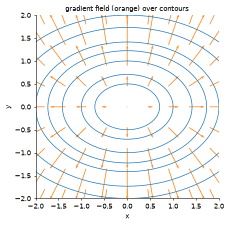

In [8]:
grad_f = lambda x_, y_: (2 * x_, 4 * y_)
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.contour(X2, Y2, f(X2, Y2), levels=[0.5, 1, 2, 3, 4, 6, 8], colors="tab:blue", linewidths=1)
gx, gy = np.meshgrid(np.linspace(-1.8, 1.8, 9), np.linspace(-1.8, 1.8, 9))
u, v = grad_f(gx, gy)
ax.quiver(gx, gy, u, v, color="tab:orange", angles="xy", scale_units="xy", scale=8, width=0.004)
ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_title("gradient field (orange) over contours")
fig.tight_layout()

A numeric test of the perpendicularity. Walk along the contour $x^2 + 2y^2 = 3$, parametrised as $(\sqrt{3}\cos s,\ \sqrt{3/2}\,\sin s)$. At every point the tangent direction of the walk is perpendicular to the gradient, so their dot product is $0$.

In [9]:
s = np.linspace(0, 2 * np.pi, 9)
px, py = np.sqrt(3) * np.cos(s), np.sqrt(1.5) * np.sin(s)         # points on the contour f = 3
tx, ty = -np.sqrt(3) * np.sin(s), np.sqrt(1.5) * np.cos(s)        # tangent of the walk
gxs, gys = grad_f(px, py)
print("f on the walk:", np.round(f(px, py), 6))
print("gradient . tangent:", np.round(gxs * tx + gys * ty, 10))
print("all zero:", np.allclose(gxs * tx + gys * ty, 0))

f on the walk: [3. 3. 3. 3. 3. 3. 3. 3. 3.]
gradient . tangent: [ 0. -0.  0.  0.  0.  0. -0.  0.  0.]
all zero: True


**Directional derivatives.** At $(1, 1)$ the slope in the direction at angle $\theta$ is $D_{\mathbf{u}} f = \nabla f\cdot\mathbf{u} = \lVert\nabla f\rVert\cos(\theta - \theta_g)$, where $\theta_g$ is the angle of the gradient. We compute it for many angles by the formula, check a few by finite differences, and see that the maximum sits exactly along the gradient and equals $\lVert\nabla f\rVert = \sqrt{20}$.

theta =   0.00 deg   formula   2.0000   finite difference   2.0000
theta =  45.00 deg   formula   4.2426   finite difference   4.2426
theta =  90.00 deg   formula   4.0000   finite difference   4.0000
theta =  63.43 deg   formula   4.4721   finite difference   4.4721

best angle: 63.0 deg   gradient angle: 63.43494882292201
max slope: 4.472007096232565   norm of gradient: 4.47213595499958


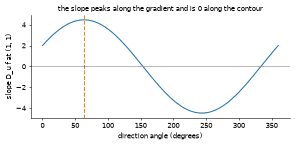

In [10]:
a = np.array([1.0, 1.0])
gvec = np.array(grad_f(*a))
thetas = np.linspace(0, 2 * np.pi, 361)
U = np.column_stack([np.cos(thetas), np.sin(thetas)])
D = U @ gvec                                                      # D_u f for every direction

for th in [0.0, np.pi / 4, np.pi / 2, np.radians(63.435)]:        # compare with a finite difference along u
    u_ = np.array([np.cos(th), np.sin(th)])
    hh = 1e-6
    fd = (f(*(a + hh * u_)) - f(*(a - hh * u_))) / (2 * hh)
    print(f"theta = {np.degrees(th):6.2f} deg   formula {gvec @ u_:8.4f}   finite difference {fd:8.4f}")

best = thetas[np.argmax(D)]
print("\nbest angle:", np.degrees(best), "deg   gradient angle:", np.degrees(np.arctan2(gvec[1], gvec[0])))
print("max slope:", D.max(), "  norm of gradient:", np.linalg.norm(gvec))

plt.figure(figsize=(6, 3))
plt.plot(np.degrees(thetas), D, color="tab:blue")
plt.axvline(np.degrees(best), color="tab:orange", ls="--"); plt.axhline(0, color="0.5", lw=0.8)
plt.xlabel("direction angle (degrees)"); plt.ylabel("slope D_u f at (1, 1)")
plt.title("the slope peaks along the gradient and is 0 along the contour")
plt.tight_layout()

## 5. The Jacobian and the local linear map

For $F(x, y) = (x^2 - y,\ xy)$ the Jacobian is $`J_F = \begin{pmatrix} 2x & -1 \\ y & x \end{pmatrix}`$. Near a point $\mathbf{a}$ the map behaves like the matrix $J_F(\mathbf{a})$ acting on small steps, which is the [linear transformation](../../linear-algebra/linear-transformations/README.md) idea. Below, a small square grid around $\mathbf{a} = (1, 2)$ is sent through the true map (blue) and through the linear model $F(\mathbf{a}) + J_F(\mathbf{a})\,\boldsymbol{\Delta}$ (orange dashed).

Jacobian: Matrix([[2*x, -1], [y, x]])    at (1, 2): Matrix([[2, -1], [2, 1]])    det: 4
true F(a + step): [-0.74   2.145]   linear model: [-0.75  2.15]


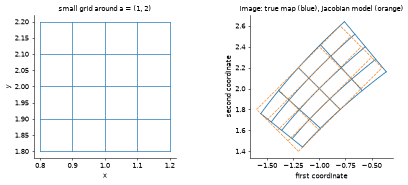

In [11]:
F_sym = sp.Matrix([x**2 - y, x * y])
J_sym = F_sym.jacobian([x, y])
print("Jacobian:", J_sym, "   at (1, 2):", J_sym.subs({x: 1, y: 2}), "   det:", J_sym.subs({x: 1, y: 2}).det())

F = sp.lambdify((x, y), F_sym, "numpy")
Fn = lambda p: np.array([p[0]**2 - p[1], p[0] * p[1]])
Ja = np.array(J_sym.subs({x: 1, y: 2}), dtype=float)
a = np.array([1.0, 2.0])

ticks = np.linspace(-0.2, 0.2, 5)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for c in ticks:
    for line in ([(c, s_) for s_ in np.linspace(-0.2, 0.2, 30)], [(s_, c) for s_ in np.linspace(-0.2, 0.2, 30)]):
        d = np.array(line)
        ax[0].plot(a[0] + d[:, 0], a[1] + d[:, 1], color="tab:blue", lw=1)
        true_img = np.array([Fn(a + di) for di in d])
        lin_img = Fn(a) + d @ Ja.T
        ax[1].plot(true_img[:, 0], true_img[:, 1], color="tab:blue", lw=1.2)
        ax[1].plot(lin_img[:, 0], lin_img[:, 1], color="tab:orange", lw=1, ls="--")
ax[0].set_title("small grid around a = (1, 2)"); ax[0].set_aspect("equal")
ax[1].set_title("image: true map (blue), Jacobian model (orange)"); ax[1].set_aspect("equal")
for k in range(2):
    ax[k].set_xlabel("first coordinate" if k else "x"); ax[k].set_ylabel("second coordinate" if k else "y")
fig.tight_layout()

step = np.array([0.1, -0.05])
print("true F(a + step):", Fn(a + step), "  linear model:", Fn(a) + Ja @ step)

The determinant of the Jacobian, here $4$, is the factor by which small areas are stretched, so a tiny square of area $0.04$ lands on a patch of about $0.16$. We check that with the corners of a small square, using the shoelace area formula.

In [12]:
def shoelace(P):
    P = np.asarray(P)
    return 0.5 * abs(np.dot(P[:, 0], np.roll(P[:, 1], -1)) - np.dot(P[:, 1], np.roll(P[:, 0], -1)))

eps = 1e-3
square = np.array([[0, 0], [eps, 0], [eps, eps], [0, eps]])
image = np.array([Fn(a + c) for c in square])
print("area ratio image / square:", shoelace(image) / eps**2, "  |det J|:", abs(np.linalg.det(Ja)))
print("close:", np.isclose(shoelace(image) / eps**2, abs(np.linalg.det(Ja)), rtol=1e-2))

area ratio image / square: 4.002500499922235   |det J|: 4.0
close: True


## 6. The Hessian and approximations

For $g(x, y) = x^3 + 2xy + y^2$ at $(1, 1)$ the gradient is $(5, 4)$ and the Hessian is $`\begin{pmatrix} 6 & 2 \\ 2 & 2 \end{pmatrix}`$. The linear model is $g(\mathbf{a}) + \nabla g\cdot\boldsymbol{\Delta}$, and the quadratic model adds $\tfrac12\boldsymbol{\Delta}^\top H\boldsymbol{\Delta}$. We measure the error of each for steps of growing length and fit the slope of the error on a log-log plot: about $2$ for the linear model and $3$ for the quadratic one.

gradient: [5. 4.] 
Hessian:
 [[6. 2.]
 [2. 2.]] 
symmetric: True
fitted slopes: linear 2.01, quadratic 3.00


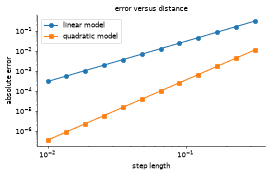

In [13]:
g_sym = x**3 + 2 * x * y + y**2
g_num = sp.lambdify((x, y), g_sym)
a = np.array([1.0, 1.0])
grad_a = np.array([float(sp.diff(g_sym, v).subs({x: 1, y: 1})) for v in (x, y)])
H_a = np.array(sp.hessian(g_sym, (x, y)).subs({x: 1, y: 1}), dtype=float)
print("gradient:", grad_a, "\nHessian:\n", H_a, "\nsymmetric:", np.allclose(H_a, H_a.T))

d = np.array([1.0, 1.0]) / np.sqrt(2)
dist = np.logspace(-2, -0.5, 12)
err_lin, err_quad = [], []
for r in dist:
    step = r * d
    true = g_num(*(a + step))
    lin = g_num(*a) + grad_a @ step
    err_lin.append(abs(true - lin))
    err_quad.append(abs(true - (lin + 0.5 * step @ H_a @ step)))
slope_lin = np.polyfit(np.log10(dist), np.log10(err_lin), 1)[0]
slope_quad = np.polyfit(np.log10(dist), np.log10(err_quad), 1)[0]
print(f"fitted slopes: linear {slope_lin:.2f}, quadratic {slope_quad:.2f}")

plt.figure(figsize=(5.5, 3.6))
plt.loglog(dist, err_lin, "o-", label="linear model", color="tab:blue")
plt.loglog(dist, err_quad, "s-", label="quadratic model", color="tab:orange")
plt.xlabel("step length"); plt.ylabel("absolute error"); plt.legend(); plt.title("error versus distance")
plt.tight_layout()

## 7. Critical points, the second-derivative test, and conditioning

A critical point has $\nabla f = \mathbf{0}$. The Hessian's eigenvalues classify it. We find the critical points of $h(x, y) = x^3 - 3x + y^2$ with SymPy, classify them, and do the same for a function with a maximum, $k(x, y) = -x^2 + 2x - 2y^2 + 1$. In each picture the solid contours are the true function and the dashed ones are the quadratic model $f(\mathbf{a}) + \tfrac12\boldsymbol{\Delta}^\top H\boldsymbol{\Delta}$.

critical point (-1, +0)  eigenvalues [-6.  2.]  ->  saddle
critical point (+1, +0)  eigenvalues [2. 6.]  ->  minimum
critical point (+1, +0)  eigenvalues [-4. -2.]  ->  maximum


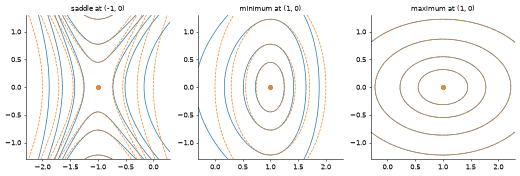

In [14]:
h_sym = x**3 - 3 * x + y**2
k_sym = -x**2 + 2 * x - 2 * y**2 + 1

def classify(expr):
    out = []
    for c in sp.solve([sp.diff(expr, v) for v in (x, y)], [x, y], dict=True):
        H = np.array(sp.hessian(expr, (x, y)).subs(c), dtype=float)
        eig = np.linalg.eigvalsh(H)
        kind = "minimum" if np.all(eig > 0) else "maximum" if np.all(eig < 0) else "saddle" if eig.min() < 0 < eig.max() else "inconclusive"
        out.append((float(c[x]), float(c[y]), H, eig, kind))
    return out

cases = [(expr, p) for expr in (h_sym, k_sym) for p in classify(expr)]
fig, axs = plt.subplots(1, 3, figsize=(10.5, 3.6))
for ax, (expr, (cx, cy, H, eig, kind)) in zip(axs, cases):
    fn = sp.lambdify((x, y), expr)
    print(f"critical point ({cx:+.0f}, {cy:+.0f})  eigenvalues {eig}  ->  {kind}")
    gx_, gy_ = np.meshgrid(np.linspace(cx - 1.3, cx + 1.3, 150), np.linspace(cy - 1.3, cy + 1.3, 150))
    quad_model = fn(cx, cy) + 0.5 * (H[0, 0] * (gx_ - cx)**2 + 2 * H[0, 1] * (gx_ - cx) * (gy_ - cy) + H[1, 1] * (gy_ - cy)**2)
    levels = fn(cx, cy) + np.array([-3, -1.5, -0.6, -0.2, 0.2, 0.6, 1.5, 3])
    ax.contour(gx_, gy_, fn(gx_, gy_), levels=np.sort(levels), colors="tab:blue", linewidths=1, negative_linestyles="solid")
    ax.contour(gx_, gy_, quad_model, levels=np.sort(levels), colors="tab:orange", linewidths=1, linestyles="--")
    ax.plot([cx], [cy], "ro"); ax.set_aspect("equal"); ax.set_title(f"{kind} at ({cx:.0f}, {cy:.0f})")
fig.tight_layout()

Look at eigenvalues, not diagonal entries: $x^2 + 4xy + y^2$ has Hessian $`\begin{pmatrix} 2 & 4 \\ 4 & 2 \end{pmatrix}`$ with a positive diagonal, but its eigenvalues are $6$ and $-2$, a saddle. A 3D view of the saddle $x^2 - y^2$ with its (here exact) quadratic model drawn on top:

eigenvalues of [[2, 4], [4, 2]]: [-2.  6.]


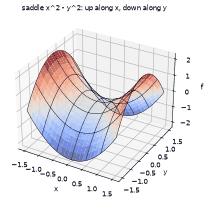

In [15]:
print("eigenvalues of [[2, 4], [4, 2]]:", np.linalg.eigvalsh(np.array([[2.0, 4.0], [4.0, 2.0]])))

gs = np.linspace(-1.5, 1.5, 25)
Xs, Ys = np.meshgrid(gs, gs)
fig = plt.figure(figsize=(5.5, 4.2))
ax = fig.add_subplot(1, 1, 1, projection="3d")
ax.plot_surface(Xs, Ys, Xs**2 - Ys**2, cmap="coolwarm", alpha=0.85, linewidth=0)
ax.plot_wireframe(Xs, Ys, 0.5 * (2 * Xs**2 - 2 * Ys**2), rstride=4, cstride=4, color="k", linewidth=0.6)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("f"); ax.set_title("saddle x^2 - y^2: up along x, down along y")
fig.tight_layout()

**Condition number and narrow valleys.** For $f = \tfrac12(x^2 + 50y^2)$ the Hessian is $\operatorname{diag}(1, 50)$ and the condition number is $\kappa = 50$. The contours are long ellipses. As a preview of the next topics, follow the negative gradient with a fixed step $0.035$ from $(4, 1)$: the path swings across the valley while it crawls along the floor. The same rule on a round bowl ($\kappa = 1$) walks straight to the bottom. (We study this rule, gradient descent, properly in the next topic; here it is only a way to see curvature.)

eigenvalues: [ 1. 50.]   condition number: 50.0   np.linalg.cond: 50.0
kappa =  1: steps to get within 1e-3 of the minimum = 4
kappa = 50: steps to get within 1e-3 of the minimum = 233


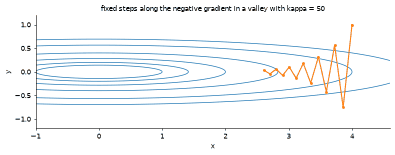

In [16]:
def valley(kappa):
    return np.diag([1.0, float(kappa)])

def follow(H, start, step, n):
    p = np.array(start, dtype=float)
    path = [p.copy()]
    for _ in range(n):
        p = p - step * (H @ p)                  # the gradient of 0.5 * p^T H p is H p
        path.append(p.copy())
    return np.array(path)

H_v = valley(50)
eig = np.linalg.eigvalsh(H_v)
print("eigenvalues:", eig, "  condition number:", eig.max() / eig.min(), "  np.linalg.cond:", np.linalg.cond(H_v))

path = follow(H_v, (4, 1), 0.035, 12)
gxv, gyv = np.meshgrid(np.linspace(-1, 4.6, 300), np.linspace(-1.2, 1.2, 200))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.contour(gxv, gyv, 0.5 * (gxv**2 + 50 * gyv**2), levels=[0.5, 1, 2, 4, 8, 12], colors="tab:blue", linewidths=1)
ax.plot(path[:, 0], path[:, 1], "o-", color="tab:orange", ms=3)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_title("fixed steps along the negative gradient in a valley with kappa = 50")
fig.tight_layout()

for kappa, step in [(1, 0.9), (50, 0.035)]:
    pth = follow(valley(kappa), (4, 1), step, 2000)
    steps = int(np.argmax(np.linalg.norm(pth, axis=1) < 1e-3)) if (np.linalg.norm(pth, axis=1) < 1e-3).any() else None
    print(f"kappa = {kappa:>2}: steps to get within 1e-3 of the minimum = {steps}")

## 8. Double integrals

The volume under $f(x, y) = x^2 + y$ over the rectangle $[0, 1]\times[0, 2]$ is a limit of sums of thin boxes. A midpoint Riemann sum on an $n\times n$ grid closes in on the exact value $\tfrac83 \approx 2.6667$, and the error shrinks by about $4$ each time $n$ doubles.

    n    Riemann sum        error
    1       2.500000     1.67e-01
    2       2.625000     4.17e-02
    4       2.656250     1.04e-02
    8       2.664062     2.60e-03
   16       2.666016     6.51e-04
   32       2.666504     1.63e-04
   64       2.666626     4.07e-05
  128       2.666656     1.02e-05


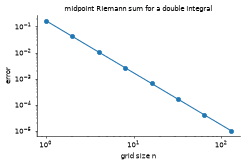

In [17]:
def riemann(func, x0, x1, y0, y1, n):
    xm = x0 + (np.arange(n) + 0.5) * (x1 - x0) / n
    ym = y0 + (np.arange(n) + 0.5) * (y1 - y0) / n
    XM, YM = np.meshgrid(xm, ym)
    return func(XM, YM).sum() * (x1 - x0) / n * (y1 - y0) / n

fr = lambda xx, yy: xx**2 + yy
exact = 8 / 3
ns = [1, 2, 4, 8, 16, 32, 64, 128]
vals = [riemann(fr, 0, 1, 0, 2, n) for n in ns]
print(f"{'n':>5} {'Riemann sum':>14} {'error':>12}")
for n, v in zip(ns, vals):
    print(f"{n:>5} {v:>14.6f} {abs(v - exact):>12.2e}")

plt.figure(figsize=(5, 3.4))
plt.loglog(ns, [abs(v - exact) for v in vals], "o-", color="tab:blue")
plt.xlabel("grid size n"); plt.ylabel("error"); plt.title("midpoint Riemann sum for a double integral")
plt.tight_layout()

**Fubini.** Integrate in either order and get the same number. We check the rectangle and a non-rectangular region, the triangle $0 \le y \le x \le 1$, where the inner limits depend on the outer variable. `dblquad` is a numerical double integral (its inner variable comes first in the function arguments).

In [18]:
rect_xy = sp.integrate(x**2 + y, (x, 0, 1), (y, 0, 2))      # inner variable first
rect_yx = sp.integrate(x**2 + y, (y, 0, 2), (x, 0, 1))
tri_dy = sp.integrate(x * y, (y, 0, x), (x, 0, 1))
tri_dx = sp.integrate(x * y, (x, y, 1), (y, 0, 1))
print("rectangle:", rect_xy, rect_yx, "   triangle:", tri_dy, tri_dx)

tri_num, _ = dblquad(lambda yy, xx: xx * yy, 0, 1, lambda xx: 0, lambda xx: xx)       # x from 0 to 1, y from 0 to x
print("dblquad on the triangle:", tri_num, " close to 1/8:", np.isclose(tri_num, 1 / 8))

area = sp.integrate(1, (y, 0, x), (x, 0, 1))
print("triangle area:", area, "  average of xy over it:", tri_dy / area, "  average of x^2 + y on the rectangle:", rect_xy / 2)

rectangle: 8/3 8/3    triangle: 1/8 1/8
dblquad on the triangle: 0.125  close to 1/8: True
triangle area: 1/2   average of xy over it: 1/4   average of x^2 + y on the rectangle: 4/3


## 9. Polar coordinates and the Gaussian integral

Under $x = r\cos\theta$, $y = r\sin\theta$ the Jacobian determinant is $r$, so $dA = r\,dr\,d\theta$. SymPy confirms it and computes two integrals over a disc.

In [19]:
r, th = sp.symbols("r theta", positive=True)
P = sp.Matrix([r * sp.cos(th), r * sp.sin(th)])
J_polar = P.jacobian([r, th])
print("Jacobian:", J_polar, "  determinant:", sp.simplify(J_polar.det()))
print("area of the disc of radius R:", sp.integrate(r, (r, 0, sp.Symbol("R", positive=True)), (th, 0, 2 * sp.pi)))
print("integral of x^2 + y^2 over the unit disc:", sp.integrate(r**2 * r, (r, 0, 1), (th, 0, 2 * sp.pi)))

Jacobian: Matrix([[cos(theta), -r*sin(theta)], [sin(theta), r*cos(theta)]])   determinant: r
area of the disc of radius R: pi*R**2
integral of x^2 + y^2 over the unit disc: pi/2


**The Gaussian integral.** Integrate $e^{-(x^2+y^2)}$ over the square $[-L, L]^2$ for growing $L$ and the values climb to $\pi$. In polar coordinates the integral over the disc of radius $R$ is exactly $\pi(1 - e^{-R^2})$. Then the one-variable integral $\int e^{-x^2}dx$ must be $\sqrt{\pi}$, which we confirm with `quad`.

In [20]:
print(f"{'L':>3} {'square [-L, L]^2':>18} {'disc of radius L':>18}")
for L in [1, 2, 3, 4, 5]:
    sq, _ = dblquad(lambda yy, xx: np.exp(-(xx**2 + yy**2)), -L, L, -L, L)
    print(f"{L:>3} {sq:>18.8f} {np.pi * (1 - np.exp(-L**2)):>18.8f}")
print("pi =", np.pi)

one_d, _ = quad(lambda z: np.exp(-z**2), -np.inf, np.inf)
print("integral of exp(-z^2):", one_d, "  sqrt(pi):", np.sqrt(np.pi), "  close:", np.isclose(one_d, np.sqrt(np.pi)))
print("integral of exp(-z^2/2):", quad(lambda z: np.exp(-z**2 / 2), -np.inf, np.inf)[0], "  sqrt(2 pi):", np.sqrt(2 * np.pi))

  L   square [-L, L]^2   disc of radius L
  1         2.23098514         1.98586530
  2         3.11227032         3.08405238
  3         3.14145386         3.14120495
  4         3.14159256         3.14159230
  5         3.14159265         3.14159265
pi = 3.141592653589793
integral of exp(-z^2): 1.7724538509055159   sqrt(pi): 1.7724538509055159   close: True
integral of exp(-z^2/2): 2.5066282746309994   sqrt(2 pi): 2.5066282746310002


**Probability over a region.** The 2D standard Gaussian density $p(x, y) = \frac{1}{2\pi}e^{-(x^2+y^2)/2}$ integrates to $1$, and the probability of the unit disc is $1 - e^{-1/2}$ by the polar integral. A seeded Monte Carlo simulation agrees to about two decimals.

In [21]:
p_disc = 1 - np.exp(-0.5)
rng = np.random.default_rng(0)
pts = rng.standard_normal((200_000, 2))
mc = np.mean(np.sum(pts**2, axis=1) <= 1)
dens = lambda yy, xx: np.exp(-(xx**2 + yy**2) / 2) / (2 * np.pi)
total, _ = dblquad(dens, -8, 8, -8, 8)
print("total probability:", total, "  exact P(unit disc):", p_disc, "  Monte Carlo:", mc)
print("close:", np.isclose(total, 1), np.isclose(mc, p_disc, atol=5e-3))

total probability: 0.9999999999999976   exact P(unit disc): 0.3934693402873666   Monte Carlo: 0.392245
close: True True


## 10. A tiny two-layer network: the chain rule as a product of Jacobians

The network is $\mathbf{z}_1 = W_1\mathbf{x} + \mathbf{b}_1$ (shape $3$), $\mathbf{h} = \tanh(\mathbf{z}_1)$, $\mathbf{z}_2 = W_2\mathbf{h} + \mathbf{b}_2$ (shape $2$), loss $L = \tfrac12\lVert\mathbf{z}_2 - \mathbf{t}\rVert^2$. We multiply the Jacobians from the loss backwards, printing every shape, and compare the resulting gradient with centered finite differences and with SymPy.

In [22]:
W1 = np.array([[0.5, -0.3], [0.2, 0.8], [-0.6, 0.1]]); b1 = np.array([0.1, 0.0, -0.1])
W2 = np.array([[0.7, -0.2, 0.4], [-0.5, 0.3, 0.9]]); b2 = np.array([0.0, 0.2])
x_in = np.array([1.0, -1.0]); target = np.array([1.0, 0.0])

z1 = W1 @ x_in + b1
h = np.tanh(z1)
z2 = W2 @ h + b2
loss = 0.5 * np.sum((z2 - target) ** 2)

J_L_z2 = (z2 - target).reshape(1, 2)          # dL/dz2
J_z2_h = W2                                   # dz2/dh
J_h_z1 = np.diag(1 - h**2)                    # dh/dz1
for name, J in [("dL/dz2", J_L_z2), ("dz2/dh", J_z2_h), ("dh/dz1", J_h_z1)]:
    print(f"{name:>7} shape {J.shape}")
delta1 = J_L_z2 @ J_z2_h @ J_h_z1             # (1x2)(2x3)(3x3) = 1x3: dL/dz1
print(f"{'delta1':>7} shape {delta1.shape}  =", delta1.ravel())

grads = {"W1": delta1.T @ x_in.reshape(1, 2), "b1": delta1.ravel(),
         "W2": J_L_z2.T @ h.reshape(1, 3), "b2": J_L_z2.ravel()}
print({k: v.shape for k, v in grads.items()})

 dL/dz2 shape (1, 2)
 dz2/dh shape (2, 3)
 dh/dz1 shape (3, 3)
 delta1 shape (1, 3)  = [-0.000637 -0.102261 -0.60821 ]
{'W1': (3, 2), 'b1': (3,), 'W2': (2, 3), 'b2': (2,)}


In [23]:
def loss_of(theta):
    W1_, b1_ = theta[:6].reshape(3, 2), theta[6:9]
    W2_, b2_ = theta[9:15].reshape(2, 3), theta[15:]
    return 0.5 * np.sum((W2_ @ np.tanh(W1_ @ x_in + b1_) + b2_ - target) ** 2)

theta = np.concatenate([W1.ravel(), b1, W2.ravel(), b2])
backprop = np.concatenate([grads["W1"].ravel(), grads["b1"], grads["W2"].ravel(), grads["b2"]])
numeric = num_grad(loss_of, theta)
print("loss:", round(loss, 6), "  loss_of(theta):", round(loss_of(theta), 6))
print("max |backprop - finite difference|:", np.max(np.abs(backprop - numeric)))

# SymPy: the same loss with symbolic parameters, differentiated exactly
sW1 = sp.Matrix(3, 2, sp.symbols("w1_0:6")); sb1 = sp.Matrix(sp.symbols("c1_0:3"))
sW2 = sp.Matrix(2, 3, sp.symbols("w2_0:6")); sb2 = sp.Matrix(sp.symbols("c2_0:2"))
sz2 = sW2 * (sW1 * sp.Matrix(x_in) + sb1).applyfunc(sp.tanh) + sb2
sL = sum((sz2[i] - target[i]) ** 2 for i in range(2)) / 2
params = list(sW1) + list(sb1) + list(sW2) + list(sb2)
subs = dict(zip(params, theta))
exact = np.array([float(sp.diff(sL, p_).subs(subs)) for p_ in params])
print("max |backprop - sympy|:", np.max(np.abs(backprop - exact)), "  all close:", np.allclose(backprop, exact))

loss: 0.636041   loss_of(theta): 0.636041
max |backprop - finite difference|: 1.509992131332183e-11


max |backprop - sympy|: 1.1102230246251565e-16   all close: True


## 11. Linear regression: set the gradient to zero

For $L(\mathbf{w}) = \lVert X\mathbf{w} - \mathbf{y}\rVert^2$ the gradient is $2X^\top(X\mathbf{w} - \mathbf{y})$. Setting it to zero gives the normal equations $X^\top X\mathbf{w} = X^\top\mathbf{y}$. With invented data, we check the gradient numerically, solve the equations, compare with `np.linalg.lstsq`, and look at the Hessian $2X^\top X$.

In [24]:
t_data = np.array([0.0, 1.0, 2.0, 3.0, 4.0, 5.0])
y_data = np.array([1.0, 2.9, 5.2, 6.8, 9.1, 11.2])
X = np.column_stack([np.ones_like(t_data), t_data])        # intercept and slope
L = lambda w: np.sum((X @ w - y_data) ** 2)
grad_L = lambda w: 2 * X.T @ (X @ w - y_data)

w0 = np.array([0.5, 1.0])
print("gradient formula :", grad_L(w0), "\nfinite difference:", num_grad(L, w0))
w_ne = np.linalg.solve(X.T @ X, X.T @ y_data)
w_ls = np.linalg.lstsq(X, y_data, rcond=None)[0]
print("normal equations:", w_ne, "  lstsq:", w_ls, "  same:", np.allclose(w_ne, w_ls))
print("gradient at the solution is zero:", np.allclose(grad_L(w_ne), 0))
H_L = 2 * X.T @ X
print("Hessian eigenvalues:", np.linalg.eigvalsh(H_L), " (all positive: a minimum)  cond(H):", np.linalg.cond(H_L), "  cond(X)^2:", np.linalg.cond(X) ** 2)

gradient formula : [ -36.4 -127.2] 
finite difference: [ -36.4 -127.2]
normal equations: [0.947619 2.034286]   lstsq: [0.947619 2.034286]   same: True
gradient at the solution is zero: True
Hessian eigenvalues: [  3.54567 118.45433]  (all positive: a minimum)  cond(H): 33.40816243344034   cond(X)^2: 33.40816243344036


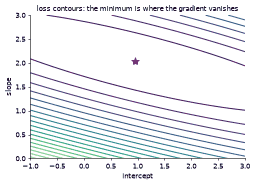

In [25]:
w1g, w2g = np.meshgrid(np.linspace(-1, 3, 150), np.linspace(0, 3, 150))
Lg = np.array([[L(np.array([a_, b_])) for a_ in w1g[0]] for b_ in w2g[:, 0]])
plt.figure(figsize=(5.2, 3.8))
plt.contour(w1g, w2g, Lg, levels=20, cmap="viridis")
plt.plot(*w_ne, "r*", ms=12)
plt.xlabel("intercept"); plt.ylabel("slope"); plt.title("loss contours: the minimum is where the gradient vanishes")
plt.tight_layout()

## 12. A per-coordinate gradient check

To test a hand-written gradient, perturb one coordinate at a time with a centered difference and compare. It costs two loss evaluations per parameter. We check the network gradient from section 10, then break it on purpose (leave out the factor $1 - \mathbf{h}^2$ from $\tanh$) and watch the check catch the bug. The relative error is $\lVert a - b\rVert / (\lVert a\rVert + \lVert b\rVert)$.

correct gradient: relative error 9.06e-12   worst coordinate 4 (error 1.51e-11)
buggy gradient  : relative error 1.84e-01   worst coordinate 4 (error 4.80e-01)
best step size h = 5.0e-06, relative error 8.7e-12


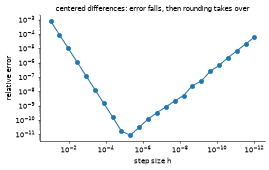

In [26]:
def rel_err(a_, b_):
    return np.linalg.norm(a_ - b_) / (np.linalg.norm(a_) + np.linalg.norm(b_))

def grad_check(loss_fn, grad_vec, theta, h=1e-5):
    num = num_grad(loss_fn, theta, h)
    per_coord = np.abs(num - grad_vec)
    return rel_err(num, grad_vec), per_coord

good = backprop
delta_bad = J_L_z2 @ J_z2_h                                    # bug: forgot the tanh derivative
bad = np.concatenate([(delta_bad.T @ x_in.reshape(1, 2)).ravel(), delta_bad.ravel(), grads["W2"].ravel(), grads["b2"].ravel()])
for name, gv in [("correct gradient", good), ("buggy gradient  ", bad)]:
    err, per = grad_check(loss_of, gv, theta)
    print(f"{name}: relative error {err:.2e}   worst coordinate {np.argmax(per)} (error {per.max():.2e})")

hs = np.logspace(-1, -12, 24)
errs = [rel_err(num_grad(loss_of, theta, h_), good) for h_ in hs]
best = hs[int(np.argmin(errs))]
print(f"best step size h = {best:.1e}, relative error {min(errs):.1e}")
plt.figure(figsize=(5.5, 3.5))
plt.loglog(hs, errs, "o-", color="tab:blue"); plt.gca().invert_xaxis()
plt.xlabel("step size h"); plt.ylabel("relative error"); plt.title("centered differences: error falls, then rounding takes over")
plt.tight_layout()

The relative error of the correct gradient sits near $10^{-10}$ or smaller at a good $h$ (around $10^{-5}$), while the buggy one is off by a large amount, at coordinates that pass through the missing factor. For very small $h$ rounding noise takes over, the same sweet spot you met in [limits and continuity](../limits-and-continuity/README.md). Used on a tiny model or a few random coordinates, this check is cheap insurance before trusting backpropagation code.

Next in the course: [gradient descent](../gradient-descent-and-its-variants/README.md), which turns the gradient into a training loop.